# D01 — Binomial, Itô y Black-Scholes con dividendos discretos y repo

**Objetivos:** construir el forward de un índice con dividendos discretos y repo; entender el lema de Itô y la
distribución lognormal; replicar una opción en un árbol de un paso y llevar el árbol CRR al límite de
Black-Scholes; valorar opciones europeas y americanas sobre el índice; estructurar la protección de una cartera
de banca privada.

**Fuentes:** Hull cap. 13, 14, 15 (15.6, 15.8 y 15.12), 17 y 21 (21.1 a 21.3); Schofield, *Equity Derivatives*,
cap. 1, 4 y 9. Datos sintéticos: índice de 5.000 puntos, repo 0,30 %, dividendos de futuros de dividendos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from derivlab.market import sample_market
from derivlab.curves import build_curves, discount_t
from derivlab.equity import EquityMarket, SSVI, bs_price, binomial, simulate_gbm, implied_vol
from derivlab import equity_market as em

estr, eur = build_curves(sample_market())
mkt = EquityMarket(estr)          # spot 5,000, repo 0.30%, market-implied dividends
surface = SSVI()                  # the desk's implied vol surface (built in D03)
print(f"Spot {mkt.spot:,.0f}; repo {mkt.repo:.2%}; dividends (time, points): {mkt.divs[:3]} ...")

Spot 5,000; repo 0.30%; dividends (time, points): [(0.55, 168.0), (1.55, 165.0), (2.55, 160.0)] ...


## 1. El forward de un índice: tipos, repo y dividendos discretos

Quien compra el índice a plazo se ahorra financiar la compra (gana el tipo €STR), pero renuncia a los dividendos
y al fee de préstamo de los títulos (repo). Con dividendos discretos $D_i$ en $t_i$:

$$F(T) = \Big(S - \sum_{t_i \le T} D_i\, P(0,t_i)\,e^{q_{\text{repo}} t_i}\Big)\,\frac{e^{-q_{\text{repo}} T}}{P(0,T)}$$

Es el modelo de dividendos *escrowed* (Hull 15.12): la volatilidad se aplica al spot menos el valor actual de los
dividendos conocidos. El forward es la cantidad que pide cualquier opción europea; un error en dividendos es un
error en el precio de todas las opciones.

In [2]:
rows = []
for T in [0.25, 0.5, 1, 2, 3, 5]:
    P = mkt.P(T)
    r = -np.log(P) / T
    F = mkt.forward(T)
    rows.append({"T": T, "estr_zero": r, "pv_dividends": mkt.pv_dividends(T), "forward": F,
                 "implied_div_yield": r - mkt.repo - np.log(F / mkt.spot) / T})
fwd = pd.DataFrame(rows)
print(fwd.to_string(index=False, formatters={"estr_zero": "{:.3%}".format, "pv_dividends": "{:,.1f}".format,
                                            "forward": "{:,.1f}".format, "implied_div_yield": lambda v: f"{max(v, 0.0):.2%}"}))
F1 = mkt.forward(1.0)
print(f"CASE 1y forward {F1:,.2f} (spot 5,000; PV of dividends {mkt.pv_dividends(1.0):.2f} points)")

   T estr_zero pv_dividends forward implied_div_yield
0.25    1.894%          0.0 5,020.0             0.00%
0.50    1.887%          0.0 5,039.8             0.00%
1.00    1.885%        166.5 4,910.7             3.39%
2.00    1.967%        327.4 4,831.0             3.39%
3.00    2.066%        480.5 4,765.3             3.37%
5.00    2.243%        765.2 4,666.9             3.32%
CASE 1y forward 4,910.69 (spot 5,000; PV of dividends 166.54 points)


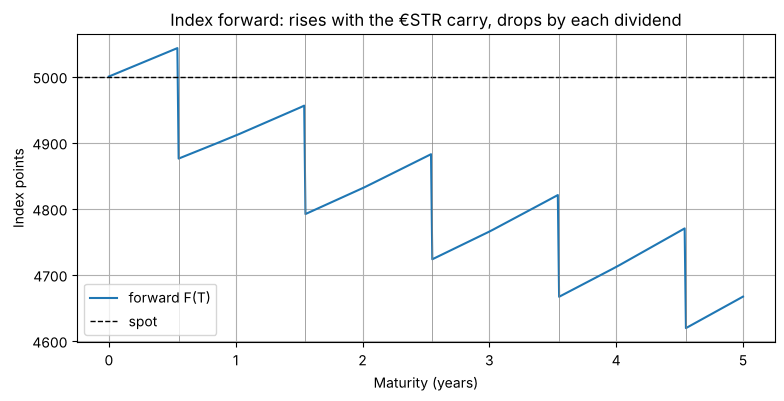

In [3]:
tt = np.linspace(0.0, 5.0, 501)
plt.plot(tt, [mkt.forward(t) for t in tt], label="forward F(T)")
plt.axhline(mkt.spot, color="k", ls="--", lw=1, label="spot")
for t, d in mkt.divs[:5]:
    plt.axvline(t, color="grey", lw=0.5)
plt.xlabel("Maturity (years)"); plt.ylabel("Index points")
plt.title("Index forward: rises with the €STR carry, drops by each dividend"); plt.legend(); plt.show()

**Lectura.** Antes del primer dividendo (mayo) el forward sube con el carry (€STR menos repo); en cada fecha de
dividendo baja el importe del dividendo. La rentabilidad por dividendo implícita ronda el 3,4 %, por encima del
€STR, así que el forward a cinco años queda unos 330 puntos por debajo del spot.

## 2. Itô y la distribución lognormal

Si $dS = \mu S\,dt + \sigma S\,dW$, el lema de Itô aplicado a $\ln S$ da
$$d\ln S = \left(\mu - \tfrac{1}{2}\sigma^2\right)dt + \sigma\, dW,$$
de modo que $\ln S_T$ es normal. La media de $S_T$ crece a $\mu$, pero la mediana crece solo a
$\mu - \sigma^2/2$: es el *volatility drag*. Se comprueba con 40.000 caminos diarios.

mean S_T 106.223 vs 100 e^(mu T) = 106.184
median S_T 104.499 vs 100 e^((mu - sigma^2/2) T) = 104.477
CASE log-return mean 0.0442 (theory 0.0438); stdev 0.1800 (theory 0.1800)


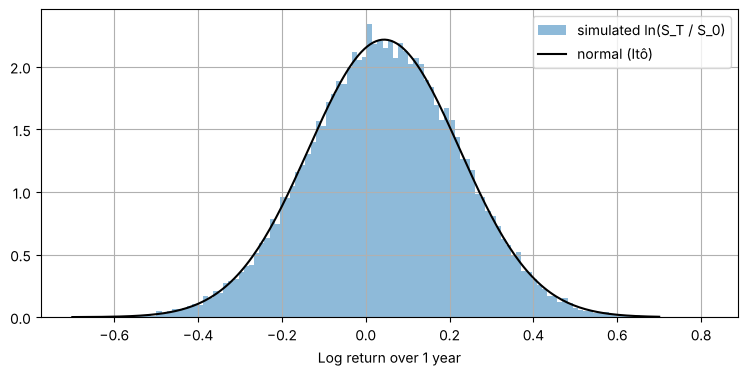

In [4]:
mu, sig, T = 0.06, 0.18, 1.0
paths = simulate_gbm(100.0, mu, sig, T, 252, 40000, seed=4)
ST = paths[:, -1]
logret = np.log(ST / 100.0)
print(f"mean S_T {ST.mean():.3f} vs 100 e^(mu T) = {100 * np.exp(mu * T):.3f}")
print(f"median S_T {np.median(ST):.3f} vs 100 e^((mu - sigma^2/2) T) = {100 * np.exp((mu - sig ** 2 / 2) * T):.3f}")
print(f"CASE log-return mean {logret.mean():.4f} (theory {mu - sig ** 2 / 2:.4f}); stdev {logret.std():.4f} (theory {sig:.4f})")
xs = np.linspace(-0.7, 0.7, 200)
plt.hist(logret, bins=120, density=True, alpha=0.5, label="simulated ln(S_T / S_0)")
plt.plot(xs, np.exp(-(xs - (mu - sig ** 2 / 2)) ** 2 / (2 * sig ** 2)) / (sig * np.sqrt(2 * np.pi)), "k", label="normal (Itô)")
plt.xlabel("Log return over 1 year"); plt.legend(); plt.show()

## 3. El árbol binomial: replicación y convergencia

**Un paso.** Con $S=100$, $u=1{,}1$, $d=0{,}9$ y tipo cero, una call de strike 100 paga 10 o 0. La cartera
$\Delta$ acciones más $B$ en caja que replica el pago tiene $\Delta = (10-0)/(110-90) = 0{,}5$ y
$B = -45$, luego la call vale $0{,}5 \cdot 100 - 45 = 5$. La probabilidad que hace martingala al subyacente es
$q = (1-d)/(u-d) = 0{,}5$, y $5 = q\cdot 10 + (1-q)\cdot 0$: valorar con $q$ es lo mismo que replicar.

**Muchos pasos.** Con $u = e^{\sigma\sqrt{\Delta t}}$ (Cox-Ross-Rubinstein, Hull 13.7) el árbol converge a
Black-Scholes. En este código el árbol se construye sobre $S^*$ (spot menos dividendos) y cada nodo lleva el
factor de crecimiento del forward, así que la probabilidad es $q=(1-d)/(u-d)$ en todos los pasos.

one step: delta 0.50, cash -45.0, call 5.00; q = 0.50, q-value 5.00


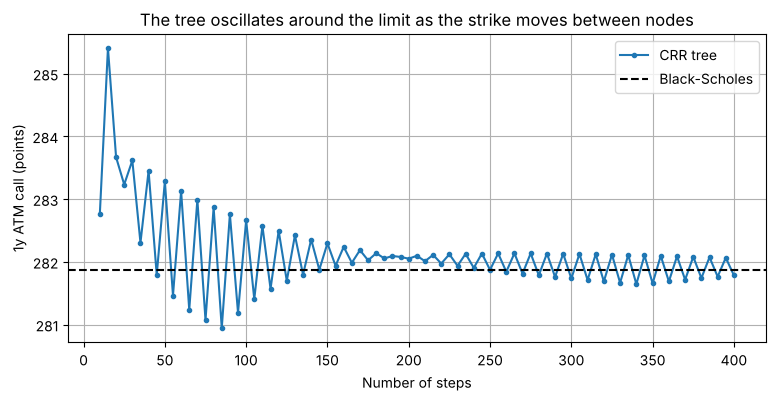

CASE 1y ATM call: BS 281.87, tree(400) 281.78, vol 16.71%


In [5]:
u, d, K1 = 1.1, 0.9, 100.0
delta1 = (max(110 - K1, 0) - max(90 - K1, 0)) / (110 - 90)
B1 = max(90 - K1, 0) - delta1 * 90
q1 = (1 - d) / (u - d)
print(f"one step: delta {delta1:.2f}, cash {B1:.1f}, call {delta1 * 100 + B1:.2f}; q = {q1:.2f}, q-value {q1 * 10:.2f}")

K, T, vol = 5000.0, 1.0, float(surface.vol(np.log(5000.0 / F1), 1.0))
bs_atm = bs_price(F1, K, T, vol, mkt.P(T), call=True)
steps_list = np.arange(10, 401, 5)
tree_vals = [binomial(mkt, K, T, vol, n, call=True) for n in steps_list]
plt.plot(steps_list, tree_vals, ".-", label="CRR tree")
plt.axhline(bs_atm, color="k", ls="--", label="Black-Scholes")
plt.xlabel("Number of steps"); plt.ylabel("1y ATM call (points)"); plt.legend()
plt.title("The tree oscillates around the limit as the strike moves between nodes"); plt.show()
print(f"CASE 1y ATM call: BS {bs_atm:.2f}, tree(400) {tree_vals[-1]:.2f}, vol {vol:.2%}")

## 4. Black-Scholes sobre el forward y paridad put-call

Con el forward como subyacente (Black-76, Hull 18.8):
$$C = P(0,T)\,[F N(d_1) - K N(d_2)], \qquad d_{1,2} = \frac{\ln(F/K) \pm \sigma^2 T/2}{\sigma\sqrt T}$$
y la paridad $C - P = P(0,T)(F-K)$ no depende del modelo. Los dividendos y el repo solo entran por $F$. Tampoco
dependen del modelo los límites de arbitraje: una call europea vale entre $P(0,T)\max(F-K,0)$ y $P(0,T)F$.

In [6]:
strikes = np.array([4000, 4500, 5000, 5500, 6000.0])
table = []
for Kx in strikes:
    v = float(surface.vol_strike(mkt, Kx, 1.0))
    c, p = bs_price(F1, Kx, 1.0, v, mkt.P(1.0), True), bs_price(F1, Kx, 1.0, v, mkt.P(1.0), False)
    table.append({"strike": Kx, "vol": v, "call": c, "put": p, "C - P": c - p, "df (F - K)": mkt.P(1.0) * (F1 - Kx)})
print(pd.DataFrame(table).to_string(index=False, formatters={"vol": "{:.2%}".format, "call": "{:.2f}".format,
      "put": "{:.2f}".format, "C - P": "{:.2f}".format, "df (F - K)": "{:.2f}".format}))
bounds_ok = all(max(row["df (F - K)"], 0) <= row["call"] <= mkt.P(1.0) * F1 and
                max(-row["df (F - K)"], 0) <= row["put"] <= mkt.P(1.0) * row["strike"] for row in table)
print(f"Arbitrage bounds max(df (F - K), 0) <= C <= df F and max(df (K - F), 0) <= P <= df K hold for every strike: {bounds_ok}")

 strike    vol   call     put    C - P df (F - K)
 4000.0 23.13% 996.78  103.10   893.68     893.68
 4500.0 19.90% 602.01  198.99   403.02     403.02
 5000.0 16.71% 281.87  369.51   -87.64     -87.64
 5500.0 13.86%  82.16  660.47  -578.30    -578.30
 6000.0 12.06%  12.88 1081.85 -1068.97   -1068.97
Arbitrage bounds max(df (F - K), 0) <= C <= df F and max(df (K - F), 0) <= P <= df K hold for every strike: True


Las volatilidades vienen de la superficie del desk (D03 explica cómo se construye): los puts de strike bajo cotizan
con más volatilidad que las calls de strike alto. Es el *skew* de renta variable.

## 5. Caso: protección de una cartera de banca privada

**Situación.** Una clienta de banca privada tiene 5 M€ en una cartera que replica el índice (1.000 veces el índice
a 5.000 puntos) y quiere protegerse durante un año frente a caídas de más del 10 %, sin vender (plusvalías
latentes). La opción listada sobre el índice tiene multiplicador 10 €/punto, así que 5 M€ son 100 contratos.

Tres propuestas: (A) comprar el put 90 % a un año; (B) put spread 90/75, más barato pero protege solo hasta −25 %;
(C) collar de coste cero: comprar el put 90 % y vender una call cuyo strike iguala las primas.

In [7]:
T, units = 1.0, 1000.0
df1 = mkt.P(T)
vol_at = lambda Kx: float(surface.vol_strike(mkt, Kx, T))
K90, K75 = 4500.0, 3750.0
put90 = bs_price(F1, K90, T, vol_at(K90), df1, call=False)
put75 = bs_price(F1, K75, T, vol_at(K75), df1, call=False)
Kc = brentq(lambda Kx: bs_price(F1, Kx, T, vol_at(Kx), df1, call=True) - put90, 5000.0, 7000.0)
print(f"CASE put 90% (strike {K90:,.0f}, vol {vol_at(K90):.2%}): {put90:.2f} points = {put90 / mkt.spot:.2%} of spot = {put90 * units:,.0f} EUR")
print(f"CASE put spread 90/75: {put90 - put75:.2f} points = {(put90 - put75) * units:,.0f} EUR")
print(f"CASE zero-cost collar: sell the {Kc:,.0f} call ({Kc / mkt.spot:.1%} of spot, vol {vol_at(Kc):.2%})")

CASE put 90% (strike 4,500, vol 19.90%): 198.99 points = 3.98% of spot = 198,986 EUR
CASE put spread 90/75: 126.26 points = 126,260 EUR
CASE zero-cost collar: sell the 5,168 call (103.4% of spot, vol 15.68%)


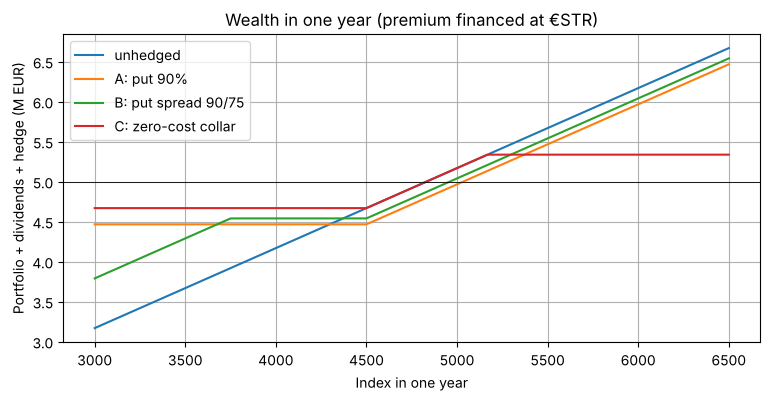

Wealth if the index ends at 3,000: A 4.47 M, B 3.79 M, C 4.67 M


In [8]:
ST = np.linspace(3000, 6500, 300)
divs_1y = sum(dv for t, dv in mkt.divs if t <= T)
base = (ST + divs_1y) * units / 1e6
prot_a = base + (np.maximum(K90 - ST, 0) - put90 / df1) * units / 1e6
prot_b = base + (np.maximum(K90 - ST, 0) - np.maximum(K75 - ST, 0) - (put90 - put75) / df1) * units / 1e6
prot_c = base + (np.maximum(K90 - ST, 0) - np.maximum(ST - Kc, 0)) * units / 1e6
for y, lab in [(base, "unhedged"), (prot_a, "A: put 90%"), (prot_b, "B: put spread 90/75"), (prot_c, "C: zero-cost collar")]:
    plt.plot(ST, y, label=lab)
plt.axhline(5.0, color="k", lw=0.6)
plt.xlabel("Index in one year"); plt.ylabel("Portfolio + dividends + hedge (M EUR)"); plt.legend()
plt.title("Wealth in one year (premium financed at €STR)"); plt.show()
worst = {lab: y.min() for y, lab in [(prot_a, "A"), (prot_b, "B"), (prot_c, "C")]}
print("Wealth if the index ends at 3,000: " + ", ".join(f"{k} {v:.2f} M" for k, v in worst.items()))

**Lectura.** El put cuesta casi un 4 % del spot porque su strike está en la zona cara del skew. El put spread
ahorra más de un tercio de la prima (126 frente a 199 puntos) pero deja de proteger por debajo de 3.750. El collar no cuesta nada, a cambio de
renunciar a las subidas por encima del 103 %: con skew, vender la call financia poco, y por eso los collars de
renta variable tienen el techo cerca del spot (al revés que un collar de tipos, donde el skew suele ser más
simétrico).

### Dividendos, repo y ejercicio americano

¿Qué pasa con la prima si el banco usa los dividendos de los analistas (más altos) en vez de los de mercado, si el
repo sube, o si la clienta pide un put americano (lo habitual en opciones sobre acciones individuales)?

In [9]:
mkt_fc = mkt.with_dividends(em.dividends(market=False))
mkt_repo = EquityMarket(estr, repo=0.0100)
put_fc = bs_price(mkt_fc.forward(T), K90, T, vol_at(K90), df1, call=False)
put_repo = bs_price(mkt_repo.forward(T), K90, T, vol_at(K90), df1, call=False)
eu_tree = binomial(mkt, K90, T, vol_at(K90), 800, call=False)
am_tree = binomial(mkt, K90, T, vol_at(K90), 800, call=False, american=True)
print(f"put 90% with analysts' dividends: {put_fc:.2f} (+{put_fc - put90:.2f}); with repo 1%: {put_repo:.2f} (+{put_repo - put90:.2f})")
print(f"CASE American put {am_tree:.2f} vs European {eu_tree:.2f}: early exercise premium {am_tree - eu_tree:.2f} points")

put 90% with analysts' dividends: 200.16 (+1.17); with repo 1%: 209.31 (+10.32)
CASE American put 202.16 vs European 199.01: early exercise premium 3.15 points


**Lectura.** Quien compra un put es largo dividendos: si los dividendos suben, el forward baja y el put vale más.
El banco que vende el put queda corto dividendos y lo cubre comprando futuros de dividendos (D4 y Parte E). Un
repo más alto también baja el forward y encarece el put. La prima por ejercicio anticipado es pequeña: ejercer
pronto adelanta el cobro del strike (se gana el €STR sobre él), pero mientras quede un dividendo por pagar
conviene esperar a que el índice caiga por el dividendo. Solo compensa después del dividendo de mayo y con el put
muy dentro del dinero.

## 6. Comprobaciones

In [10]:
assert abs(paths[:, -1].mean() / (100 * np.exp(mu * 1.0)) - 1) < 0.005
assert abs(tree_vals[-1] / bs_atm - 1) < 2e-3
for row in table:
    assert abs(row["C - P"] - row["df (F - K)"]) < 1e-8
assert abs(bs_price(F1, Kc, T, vol_at(Kc), df1, True) - put90) < 1e-8
assert put_fc > put90 and put_repo > put90
assert am_tree >= eu_tree and bounds_ok
assert abs(eu_tree / put90 - 1) < 2e-3
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** Un título difícil de tomar prestado tiene repo del 3 %. ¿Cuánto baja el forward a dos años del índice
   si el repo pasara del 0,30 % al 3 %?
2. **Intermedio.** Calcula la prima del put 85 % a un año y el strike de la call del collar de coste cero
   correspondiente.
3. **Avanzado.** Valora el put americano 90 % con un árbol de rentabilidad continua (sin dividendos discretos, con
   una rentabilidad que reproduzca el mismo forward a un año) y compáralo con el árbol de dividendos discretos.
   ¿Por qué las europeas coinciden y las americanas no?

## Soluciones

In [11]:
F2 = mkt.forward(2.0)
F2_hard = EquityMarket(estr, repo=0.03).forward(2.0)
print(f"2y forward: repo 0.30% {F2:,.1f}; repo 3% {F2_hard:,.1f}; difference {F2 - F2_hard:,.1f} points "
      f"(about S x 2.7% x 2y = {mkt.spot * 0.027 * 2:,.0f})")

2y forward: repo 0.30% 4,831.0; repo 3% 4,567.9; difference 263.1 points (about S x 2.7% x 2y = 270)


In [12]:
K85 = 4250.0
put85 = bs_price(F1, K85, T, vol_at(K85), df1, call=False)
Kc85 = brentq(lambda Kx: bs_price(F1, Kx, T, vol_at(Kx), df1, call=True) - put85, 5000.0, 7000.0)
print(f"put 85%: {put85:.2f} points ({put85 / mkt.spot:.2%}); zero-cost collar call at {Kc85:,.0f} ({Kc85 / mkt.spot:.1%})")

put 85%: 144.07 points (2.88%); zero-cost collar call at 5,302 (106.0%)


In [13]:
r1 = -np.log(df1)
q_eq = r1 - np.log(F1 / mkt.spot) / T                      # continuous yield (dividends + repo) with the same 1y forward
mkt_yield = EquityMarket(estr, repo=q_eq, divs=[])
eu_y = binomial(mkt_yield, K90, T, vol_at(K90), 800, call=False)
am_y = binomial(mkt_yield, K90, T, vol_at(K90), 800, call=False, american=True)
print(f"continuous yield {q_eq:.3%}: European {eu_y:.2f} (discrete {eu_tree:.2f}); American {am_y:.2f} (discrete {am_tree:.2f})")
print("Same forward, same European price. With a continuous yield above the €STR rate, waiting is always worth")
print("more, so the American put is worth the European. With a lump dividend in May there is nothing left to wait")
print("for after May, and from then on a deep in-the-money put is better exercised to earn €STR on the strike.")

continuous yield 3.688%: European 199.01 (discrete 199.01); American 199.01 (discrete 202.16)
Same forward, same European price. With a continuous yield above the €STR rate, waiting is always worth
more, so the American put is worth the European. With a lump dividend in May there is nothing left to wait
for after May, and from then on a deep in-the-money put is better exercised to earn €STR on the strike.
